
鸢尾花数据集（Iris dataset）是一个经典的多分类问题数据集，包含了150个样本，每个样本有4个特征（花萼长度、花萼宽度、花瓣长度、花瓣宽度）和一个标签（鸢尾花的种类，共有三种）。在使用全连接神经网络（也称为多层感知机，MLP）处理鸢尾花数据集时，全连接神经网络的结构大致如下：

- 输入层：4个神经元（对应4个特征）
- 隐藏层：可以根据需要添加一个或多个隐藏层，每个隐藏层的神经元数量可以根据实际情况调整
- 输出层：3个神经元（对应3个类别），使用softmax激活函数





# 一、 数据加载与预处理

## 1.1 数据加载

In [1]:
import torch
import torch.nn as nn
import torch.optim as optim
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
import numpy as np

# 加载鸢尾花数据集
iris = load_iris()
X = iris.data  # 特征数据
y = iris.target  # 标签数据

In [15]:
import torch
import random
import numpy as np
import os

def random_seeds(seed):
    torch.manual_seed(seed) # 为 PyTorch 的 CPU 操作设置随机种子 
    torch.cuda.manual_seed(seed) # 为 PyTorch 的单个 CUDA 设备设置随机种子  
    torch.cuda.manual_seed_all(seed) # 为 PyTorch 的所有 CUDA 设备设置随机种子
    torch.backends.cudnn.benchmark = False
    torch.backends.cudnn.deterministic = True   
    random.seed(seed) # 为 Python 内置的随机数生成器设置种子
    np.random.seed(seed)  # 为 NumPy 的随机数生成器设置种子
    os.environ['PYTHONHASHSEED'] = str(seed) # 设置 Python 解释器的哈希种子,保证哈希表的顺序在不同运行中一致

# 调用函数，将随机种子设置为 0
random_seeds(0)

## 1.2 数据划分与张量格式转换

数据说明：在 PyTorch 中，多分类任务的目标标签需采用 `LongTensor` (int64) 格式以配合交叉熵损失计算；输入特征数据需转换为 `FloatTensor` (float32) 格式以满足模型浮点权重计算要求。

In [3]:
# 划分训练集和测试集
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# 检查训练集与测试集维度
print(X_train.shape)
print(y_train.shape)
print(X_test.shape)
print(y_test.shape)

(120, 4)
(120,)
(30, 4)
(30,)


In [4]:
# 标准化数据，神经网络对于输入数据的尺寸敏感
from sklearn.preprocessing import StandardScaler
scaler=StandardScaler()
X_train=scaler.fit_transform(X_train)
X_test=scaler.transform(X_test) #确保训练集和测试集是相同的缩放

In [5]:
# 将数据转换为 PyTorch 张量，因为 PyTorch 使用张量进行训练
# 目标标签为类别索引，需转换为 LongTensor 以满足 nn.CrossEntropyLoss 输入要求
X_train = torch.FloatTensor(X_train)
y_train = torch.LongTensor(y_train)
X_test = torch.FloatTensor(X_test)
y_test = torch.LongTensor(y_test)

# 二、 模型定义

定义一个简单的全连接神经网络模型，包含一个输入层、一个隐藏层和一个输出层。

## 2.1 模型架构定义
定义层数+定义前向传播顺序

In [6]:
class IrisNet(nn.Module):
    def __init__(self):
        super(IrisNet, self).__init__()
 # 定义网络层结构

        self.fc1 = nn.Linear(4, 10)  # 输入层到隐藏层
        self.relu = nn.ReLU()
        self.fc2 = nn.Linear(10, 3)  # 隐藏层到输出层
# 输出层不使用显式 Softmax 激活函数，nn.CrossEntropyLoss 内部已集成 LogSoftmax 操作

    def forward(self, x):
        out = self.fc1(x)
        out = self.relu(out)
        out = self.fc2(out)
        return out

# 初始化模型
model = IrisNet()

定义多层感知机网络结构，采用ReLU作为非线性激活函数。

In [7]:
    # def forward(self,x): #前向传播
    #     x=torch.relu(self.fc1(x)) #激活函数
    #     x=self.fc2(x) #输出层不需要激活函数，因为后面会用到交叉熵函数cross_entropy
    #     return x

## 2.2 模型架构可视化
torchsummary库可以以表格形式输出模型的结构，展示每一层的输入输出尺寸、参数数量等信息。

In [8]:
# !pip install torchsummary

In [9]:
from torchsummary import summary
# 打印模型摘要
summary(model, input_size=(4,))

----------------------------------------------------------------
        Layer (type)               Output Shape         Param #
            Linear-1                   [-1, 10]              50
              ReLU-2                   [-1, 10]               0
            Linear-3                    [-1, 3]              33
Total params: 83
Trainable params: 83
Non-trainable params: 0
----------------------------------------------------------------
Input size (MB): 0.00
Forward/backward pass size (MB): 0.00
Params size (MB): 0.00
Estimated Total Size (MB): 0.00
----------------------------------------------------------------


可学习参数统计分析：
1. Linear-1 (`self.fc1 = nn.Linear(4, 10)`): 4 × 10 (权重) + 10 (偏置) = 50 个参数；
2. ReLU 激活层: 无可学习参数；
3. Linear-2 (`self.fc2 = nn.Linear(10, 3)`): 10 × 3 (权重) + 3 (偏置) = 33 个参数；

模型总可训练参数量为 83，权重默认采用 PyTorch Kaiming 均匀初始化策略。

# 三、 模型训练

## 3.1 定义损失函数和优化器

In [10]:
# 分类问题使用交叉熵损失函数
criterion = nn.CrossEntropyLoss()

# 使用随机梯度下降优化器
optimizer = optim.SGD(model.parameters(), lr=0.01)

# # 使用自适应学习率的化器
# optimizer = optim.Adam(model.parameters(), lr=0.001)

在实际模型训练过程中，可同步在验证集/测试集上评估每个 Epoch 的损失与分类准确率，用于实时监控模型泛化性能与防止过拟合。

In [11]:
# 训练模型
num_epochs = 1000

# 用于存储每个 epoch 的损失值
losses = []

for epoch in range(num_epochs): # 迭代训练指定轮数
    # 前向传播
    outputs = model.forward(X_train)   # 显式调用forward函数
    # outputs = model(X_train)  # 前向传播计算
    loss = criterion(outputs, y_train) # output是模型预测值，y_train是真实标签

    # 反向传播和优化
    optimizer.zero_grad() #梯度清零，因为PyTorch会累积梯度，所以每次迭代需要清零，支持通过梯度累积以小 batch_size 模拟大 batch_size 训练
    loss.backward() # 反向传播计算梯度
    optimizer.step() # 更新参数

    # 记录损失值
    losses.append(loss.item())

    # 打印训练信息
    if (epoch + 1) % 100 == 0: # 每 100 个 Epoch 输出一次训练损失
        print(f'Epoch [{epoch+1}/{num_epochs}], Loss: {loss.item():.4f}')

Epoch [100/1000], Loss: 0.7931
Epoch [200/1000], Loss: 0.6338
Epoch [300/1000], Loss: 0.5442
Epoch [400/1000], Loss: 0.4814
Epoch [500/1000], Loss: 0.4353
Epoch [600/1000], Loss: 0.3994
Epoch [700/1000], Loss: 0.3705
Epoch [800/1000], Loss: 0.3457
Epoch [900/1000], Loss: 0.3229
Epoch [1000/1000], Loss: 0.3025


如果你重新运行上面这段训练循环，模型参数、优化器状态和梯度会继续保留，导致训练结果叠加，模型参数和优化器状态（如动量、学习率等）不会被重置。这会导致训练从之前的状态继续，而不是从头开始

# 四、 可视化训练结果

训练损失可视化：记录各 Epoch 标量损失并绘制收敛曲线以评估优化趋势。

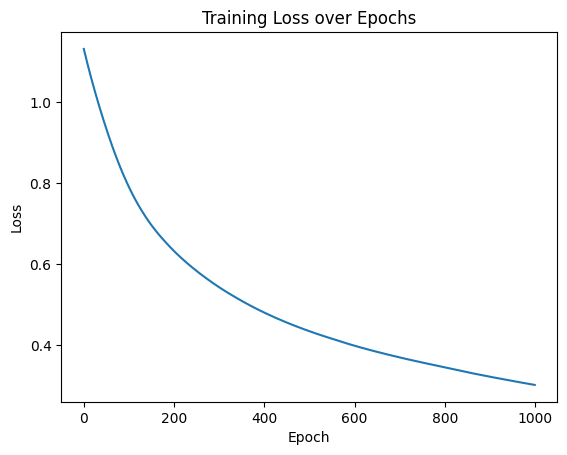

In [12]:
import matplotlib.pyplot as plt
# 可视化损失曲线
plt.plot(range(num_epochs), losses)
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.title('Training Loss over Epochs')
plt.show()

# 五、 独立测试集模型评估
在未参与训练的独立测试集上进行前向推理并计算模型泛化准确率。

In [13]:
with torch.no_grad(): # 禁用梯度计算，节省内存，用于推理阶段
    outputs = model.forward(X_test)   # 对测试数据进行前向传播，获得预测结果
    # 获取各样本输出概率最大的预测类别索引 (dim=1)
    _, predicted = torch.max(outputs, 1) 
    
    # predicted == y_test判断预测值和真实值是否相等，返回一个tensor，1表示相等，0表示不等，然后求和，再除以y_test.size(0)得到准确率
    # 因为这个时候数据都在GPU上，所以需要用item()方法将tensor转化为Python的标量
    # 计算测试集分类准确率
    # size(0)获取样本数量
    accuracy = (predicted == y_test).sum().item() / y_test.size(0)
    print(f'Test Accuracy: {accuracy:.2f}')

Test Accuracy: 0.93


批次数据管道（DataLoader）机制说明：

本示例采用小规模样本一次性全量加载。而在实际计算机视觉任务中，高分辨率图像数据集规模庞大，直接全量读入会耗尽 GPU 显存。因此，生产实践中通常使用 `torch.utils.data.Dataset` 与 `DataLoader` 构建流式批次（Mini-batch）加载管道，结合多进程异步加载与数据增强，提高 GPU 算力利用率并支持大规模模型的高效优化。

In [21]:
import random

# 用于存储生成的 3 个随机整数
random_numbers = []
# 循环 3 次
for i in range(3):
    # 生成 1 到 30 之间的随机整数
    num = random.randint(1, 30)
    # 将生成的随机整数添加到列表中
    random_numbers.append(num)

print(random_numbers)

[22, 11, 16]
